# Predicting NBA Success Based on Rookie Stats

This notebook represents my workflow and data science techniques in building a sufficent classification model for our target.

Separate Notebook to compare the difference with a 3 Tier Classification Model

Author: Rasheed Martin

In [1]:
import polars as pl
from pathlib import Path
# Load the data
path = Path.cwd().parent.parent / "data/refined_raw_data" /  "Player_Type_Modeling" / "player_3tier_label_with_target_all_years.csv"
df = pl.read_csv(path)
df

Player,Season,Player_Age,2P,2P%,2PA,3P,3P%,3PA,3PAr,AST,AST%,BLK,BLK%,BPM,DBPM,DRB,DRB%,DWS,FG,FG%,FGA,FT,FT%,FTA,FTr,G,GS,MP,OBPM,ORB,ORB%,OWS,PER,PF,PTS,STL,…,FT%_third,FTA_third,FTr_third,G_third,GS_third,MP_third,OBPM_third,ORB_third,ORB%_third,OWS_third,PER_third,PF_third,PTS_third,Player_Age_third,STL_third,STL%_third,TOV_third,TOV%_third,TRB_third,TRB%_third,TS%_third,Trp-Dbl_third,USG%_third,VORP_third,WS_third,WS/48_third,eFG%_third,All_Nba_Team_Max,AllStar_Max,Games_Played_Mean,Win_Share_Sum,Box_Plus_Minus_Mean,Minutes_Played_Mean,Games_Started_Mean,Usage_Mean,Player_Score,Player_Label
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,str
"""AC. Green""",1985,22.0,208.0,0.545,382.0,1.0,0.167,6.0,0.015,54.0,4.2,49.0,1.7,-1.6,0.1,221.0,15.5,2.0,209.0,0.539,388.0,102.0,0.611,167.0,0.43,82.0,1.0,1542.0,-1.6,160.0,12.4,1.4,11.8,229.0,521.0,49.0,…,0.773,379.0,0.592,82.0,64.0,2636.0,0.4,245.0,11.1,4.5,14.5,204.0,937.0,24.0,87.0,1.6,120.0,12.9,710.0,15.3,0.581,0.0,14.7,1.5,7.9,0.144,0.503,0,true,79.875,99.399994,-0.3875,2284.5,52.0,14.6375,0.6583543,"""Star Player"""
"""AJ Griffin""",2022,19.0,147.0,0.536,274.0,101.0,0.39,259.0,0.486,73.0,7.0,12.0,0.7,-0.8,-0.5,116.0,9.2,0.9,248.0,0.465,533.0,42.0,0.894,47.0,0.088,72.0,12.0,1401.0,-0.3,37.0,2.9,1.3,12.6,87.0,639.0,42.0,…,1.0,2.0,0.032,20.0,0.0,171.0,-6.0,2.0,1.2,-0.4,1.2,6.0,48.0,20.0,1.0,0.3,8.0,11.3,18.0,5.7,0.382,0.0,17.3,-0.3,-0.4,-0.12,0.371,0,false,46.0,1.8000001,-5.2,786.0,6.0,17.599998,0.3193468,"""Role Player"""
"""AJ Johnson""",2024,20.0,58.0,0.472,123.0,24.0,0.267,90.0,0.423,76.0,17.1,3.0,0.4,-8.1,-2.5,51.0,8.3,0.0,82.0,0.385,213.0,32.0,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,12.0,…,0.865,37.0,0.174,29.0,11.0,639.0,-5.6,8.0,1.3,-0.5,7.1,50.0,220.0,20.0,12.0,0.9,35.0,13.2,59.0,4.8,0.48,0.0,17.4,-1.0,-0.4,-0.032,0.441,0,false,29.0,-1.2,-8.1,639.0,11.0,17.4,0.311874,"""Role Player"""
"""AJ. Bramlett""",1999,23.0,4.0,0.19,21.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-15.9,-6.7,10.0,18.5,0.1,4.0,0.19,21.0,0.0,0.0,0.0,0.0,8.0,0.0,61.0,-9.2,12.0,21.7,-0.2,-0.4,13.0,8.0,1.0,…,null,0.0,0.0,8.0,0.0,61.0,-9.2,12.0,21.7,-0.2,-0.4,13.0,8.0,23.0,1.0,0.8,3.0,12.5,22.0,20.1,0.19,0.0,17.1,-0.2,-0.2,-0.129,0.19,0,false,8.0,-0.2,-15.9,61.0,0.0,17.1,0.24367,"""Bust Player"""
"""AJ. English""",1990,23.0,248.0,0.458,541.0,3.0,0.097,31.0,0.054,177.0,18.0,15.0,0.6,-3.9,-1.9,81.0,6.2,0.7,251.0,0.439,572.0,111.0,0.707,157.0,0.274,70.0,12.0,1443.0,-2.1,66.0,5.0,-0.5,10.6,127.0,616.0,25.0,…,0.841,176.0,0.208,81.0,6.0,1665.0,-1.6,74.0,4.8,0.1,12.5,160.0,886.0,24.0,32.0,0.9,89.0,8.8,168.0,5.5,0.48,0.0,25.6,-0.8,0.9,0.025,0.436,0,false,75.5,1.1,-3.85,1554.0,9.0,23.7,0.3893701,"""Role Player"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""Zoran Dragic""",2014,25.0,8.0,0.5,16.0,3.0,0.214,14.0,0.467,5.0,11.2,0.0,0.0,-7.7,-3.6,3.0,4.6,0.0,11.0,0.367,30.0,3.0,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,2.0,…,0.6,5.0,0.167,16.0,1.0,75.0,-4.1,5.0,7.8,-0.1,8.2,6.0,28.0,25.0,2.0,1.4,5.0,13.4,8.0,6.2,0.435,0.0,22.9,-0.1,-0.1,-0.042,0.417,0,false,16.0,-0.1,-7.7,75.0,1.0,22.9,0.301402,"""Role Player"""
"""Zoran Planinic""",2003,21.0,44.0,0.454,97.0,9.0,0.281,32.0,0.248,68.0,23.9,3.0,0.5,-3.4,-0.1,41.0,10.2,0.6,53.0,0.411,129.0,38.0,0.633,60.0,0.465,49.0,1.0,473.0,-3.3,14.0,3.5,0.1,10.0,70.0,153.0,13.0,…,0.697,66.0,0.361,56.0,1.0,596.0,-6.1,14.0,2.7,-0.8,6.9,91.0,191.0,23.0,20.0,1.8,43.0,16.9,74.0,7.3,0.45,0.0,20.2,-0.6,0.1,0.005,0.396,0,false,49.333332,1.6,-3.366667,528.0,3.3333333,20.466667,0.324416,"""Role Player"""
"""Zydrunas Ilgauskas""",1997,22.0,453.0,0.519,872.0,1.0,0.25,4.0,0.005,71.0,5.7,135.0,4.3,1.4,0.5,444.0,22.6,4

## Import the Transformer
We have already did our feature selection and preprocessing. So we will just import the transformer and run some models

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from pipeline import print_metrics, pipeline
from pipeline import print_roc_curve, print_precision_recall_curve


X = df.drop("Player_Label")
y = df["Player_Label"]

# Outside the pipeline
player_label_order = [["Bust Player", "Role Player", "Star Player"]]
player_label_encoder = OrdinalEncoder(categories=player_label_order)

y = player_label_encoder.fit_transform(df[["Player_Label"]]).flatten()
target_names=player_label_encoder.categories_[0] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

transformer = pipeline()

X_train_processed = transformer.fit_transform(X_train)
X_test_processed = transformer.transform(X_test)

### Random Forest

              precision    recall  f1-score   support

 Bust Player       0.84      0.85      0.84       271
 Role Player       0.70      0.73      0.72       277
 Star Player       0.83      0.78      0.80       223

    accuracy                           0.79       771
   macro avg       0.79      0.79      0.79       771
weighted avg       0.79      0.79      0.79       771

Accuracy: 0.7859922178988327
Precision (macro): 0.7909851722351723
Recall (macro): 0.7857817420025555
F1 Score (macro): 0.7879530453417072


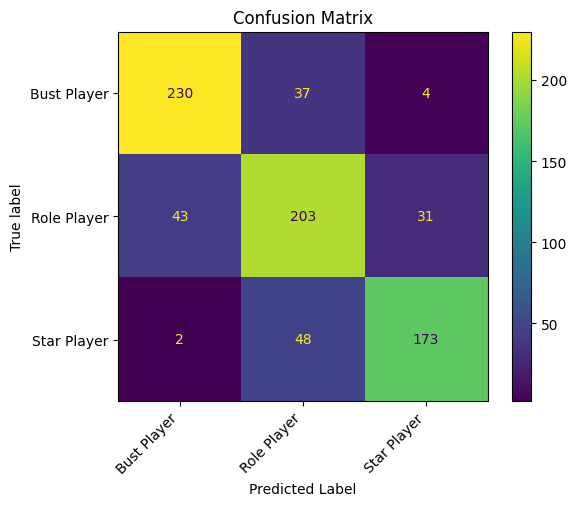

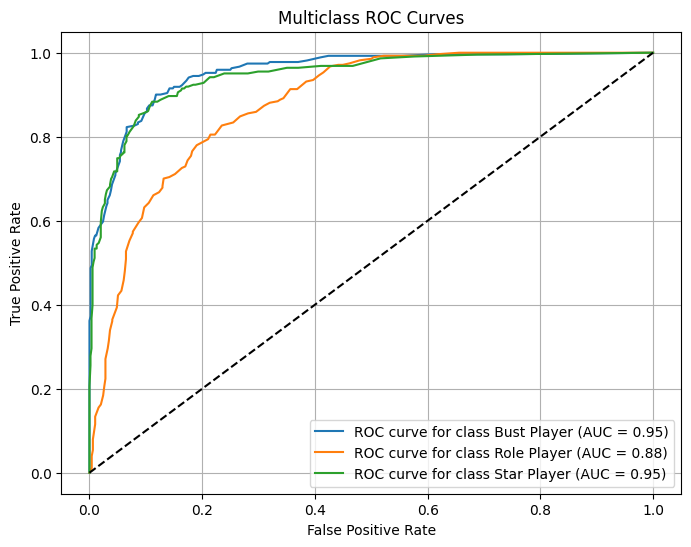

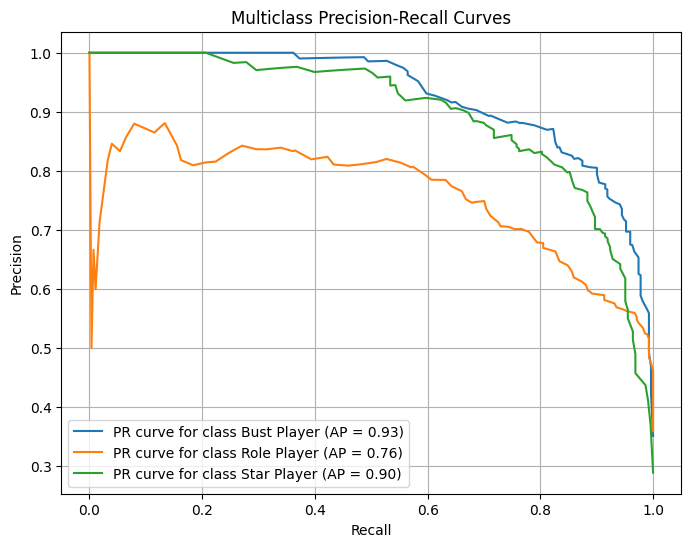

In [4]:
from sklearn.ensemble import RandomForestClassifier


model = RandomForestClassifier(random_state=42)
model.fit(X_train_processed, y_train)
y_pred = model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, model, X_test_processed, target_names)
print_precision_recall_curve(y_test, model, X_test_processed, target_names)

### XGB

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [16:27:07] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


              precision    recall  f1-score   support

 Bust Player       0.85      0.85      0.85       271
 Role Player       0.72      0.77      0.75       277
 Star Player       0.87      0.79      0.83       223

    accuracy                           0.80       771
   macro avg       0.81      0.80      0.81       771
weighted avg       0.81      0.80      0.81       771

Accuracy: 0.8041504539559015
Precision (macro): 0.8118520940529054
Recall (macro): 0.8035031107138709
F1 Score (macro): 0.8067941555400107


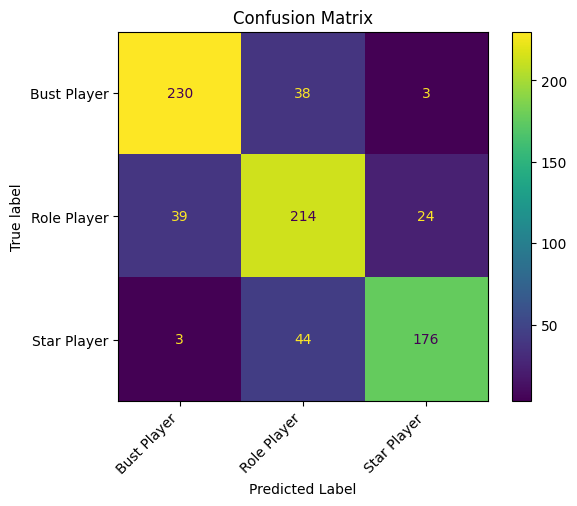

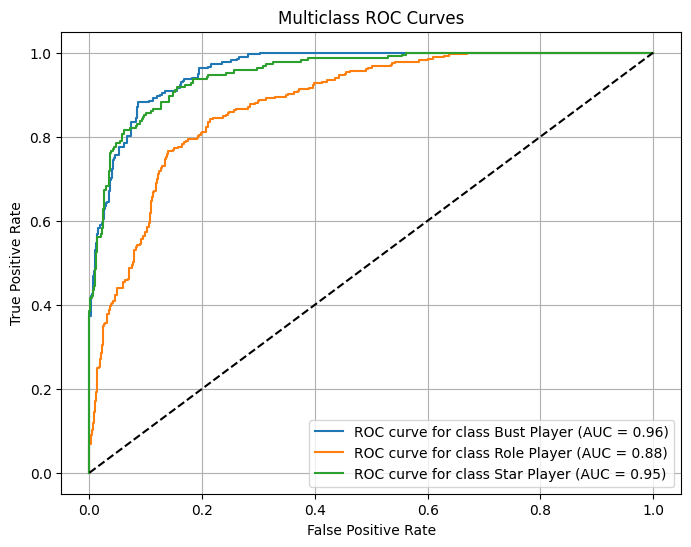

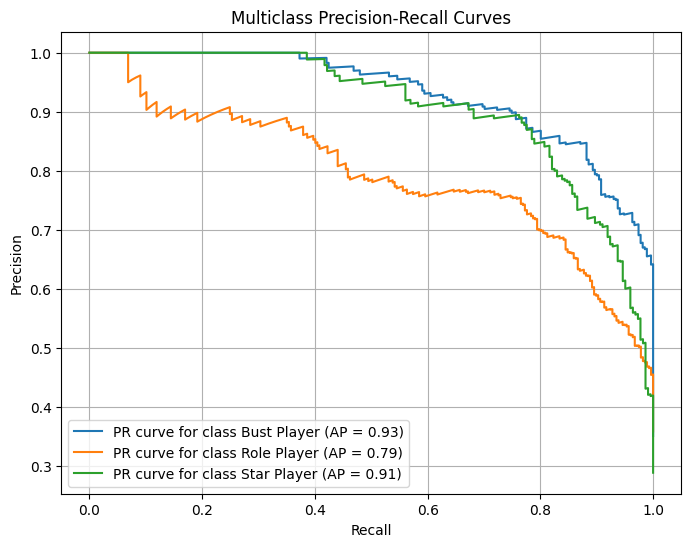

In [21]:
from xgboost import XGBClassifier

model = XGBClassifier(use_label_encoder=True, eval_metric='mlogloss')
model.fit(X_train_processed, y_train)
preds = model.predict(X_test_processed)
print_metrics(y_test, preds, target_names)
print_roc_curve(y_test, model, X_test_processed, target_names)
print_precision_recall_curve(y_test, model, X_test_processed, target_names)

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [16:27:08] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 1 Report
              precision    recall  f1-score   support

 Bust Player       0.83      0.85      0.84       271
 Role Player       0.72      0.72      0.72       277
 Star Player       0.83      0.81      0.82       223

    accuracy                           0.79       771
   macro avg       0.79      0.79      0.79       771
weighted avg       0.79      0.79      0.79       771

Accuracy: 0.7924773022049286
Precision (macro): 0.7946851333172483
Recall (macro): 0.7941564230523075
F1 Score (macro): 0.7943615703570526


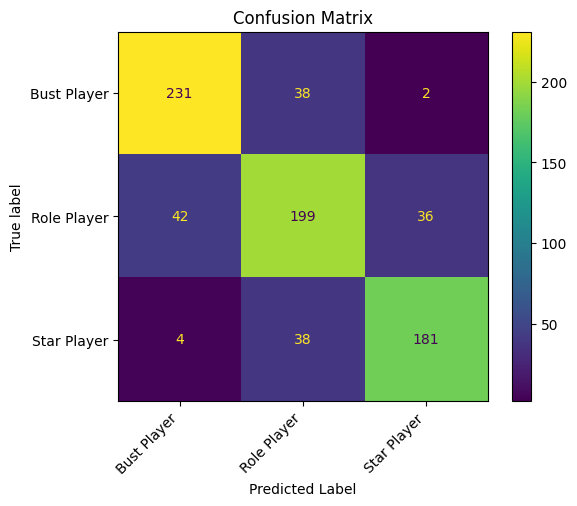

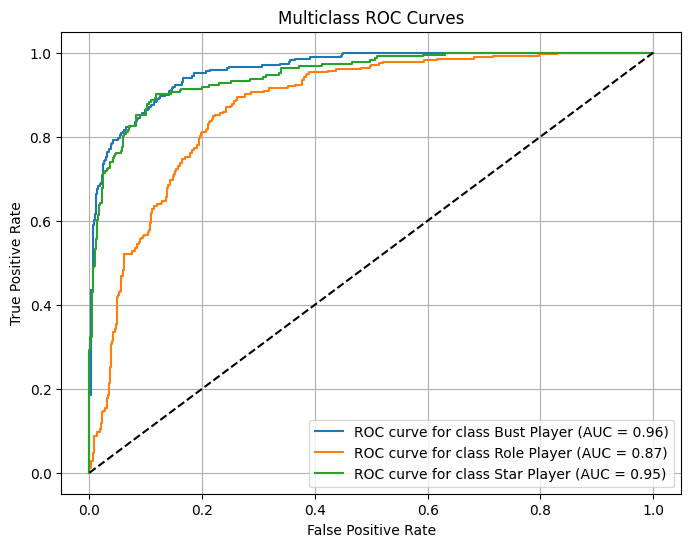

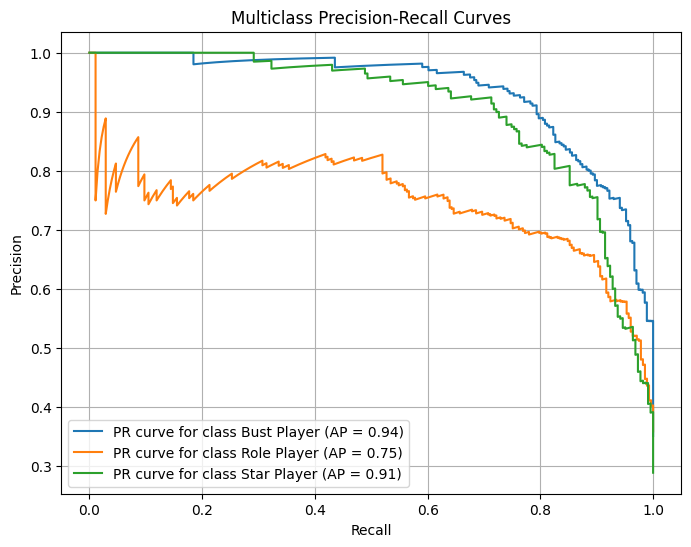

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [16:27:09] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 2 Report
              precision    recall  f1-score   support

 Bust Player       0.84      0.84      0.84       271
 Role Player       0.68      0.69      0.69       277
 Star Player       0.78      0.75      0.77       223

    accuracy                           0.76       771
   macro avg       0.76      0.76      0.76       771
weighted avg       0.76      0.76      0.76       771

Accuracy: 0.7626459143968871
Precision (macro): 0.7645978922574668
Recall (macro): 0.7626108120691703
F1 Score (macro): 0.7635173714475011


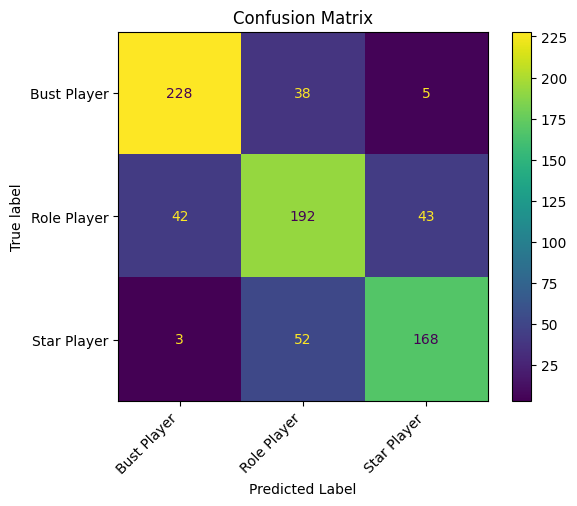

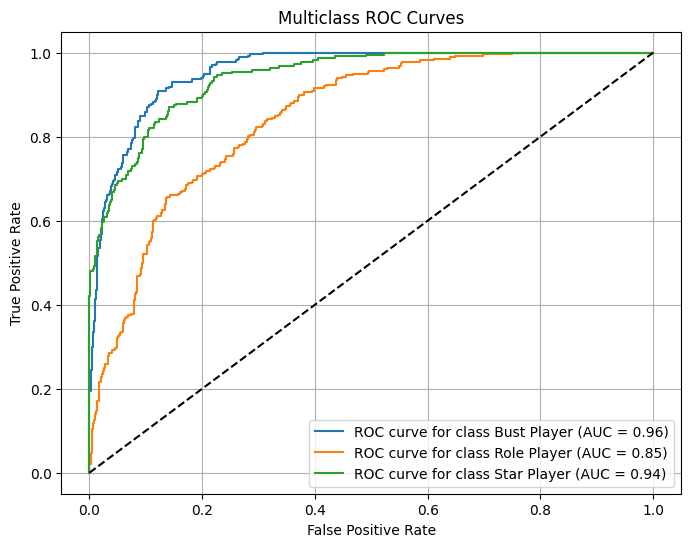

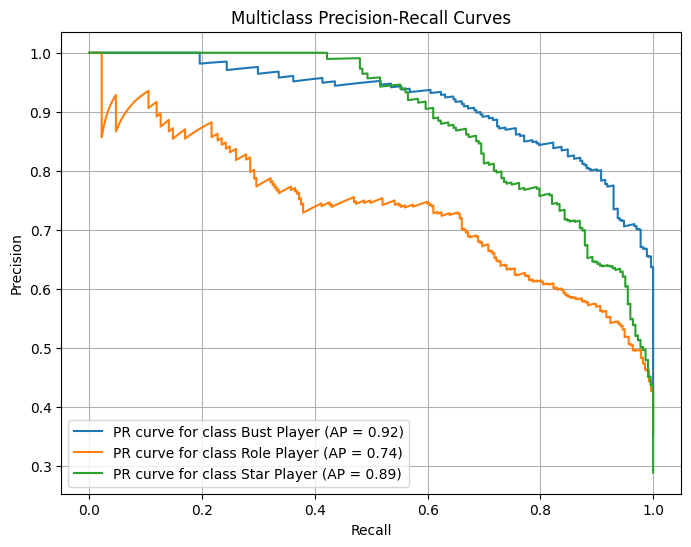

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [16:27:09] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 3 Report
              precision    recall  f1-score   support

 Bust Player       0.89      0.85      0.87       271
 Role Player       0.74      0.82      0.78       277
 Star Player       0.87      0.81      0.84       223

    accuracy                           0.83       771
   macro avg       0.84      0.83      0.83       771
weighted avg       0.83      0.83      0.83       771

Accuracy: 0.8274967574578469
Precision (macro): 0.8359767619186772
Recall (macro): 0.8263293560393473
F1 Score (macro): 0.8298493247867875


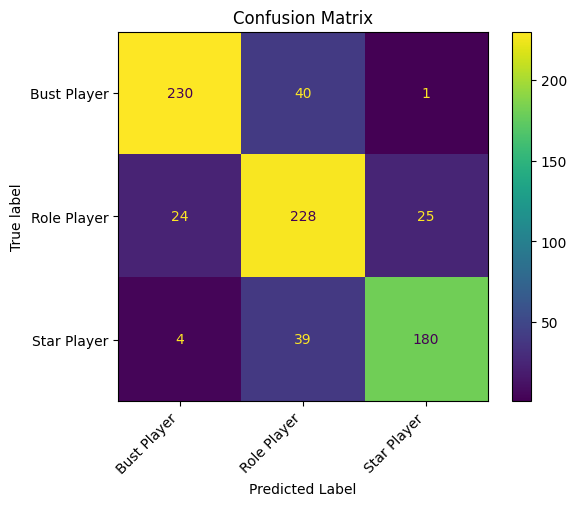

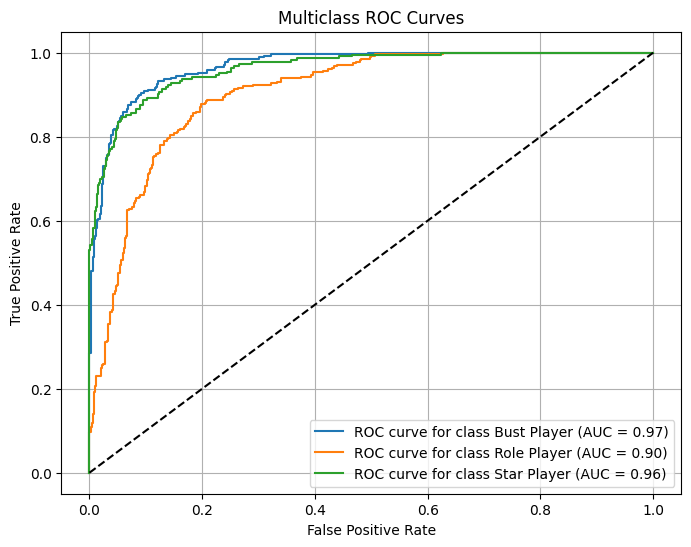

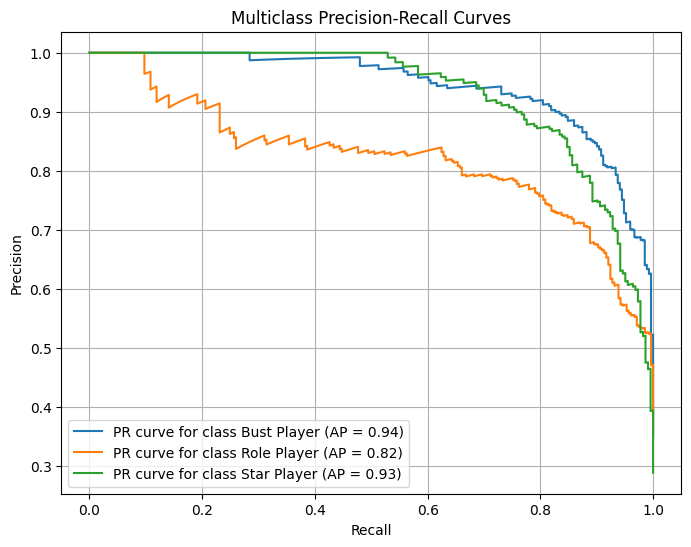

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [16:27:10] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 4 Report
              precision    recall  f1-score   support

 Bust Player       0.86      0.87      0.86       271
 Role Player       0.78      0.78      0.78       278
 Star Player       0.86      0.83      0.85       222

    accuracy                           0.83       771
   macro avg       0.83      0.83      0.83       771
weighted avg       0.83      0.83      0.83       771

Accuracy: 0.8287937743190662
Precision (macro): 0.8317863856067665
Recall (macro): 0.8294515678969739
F1 Score (macro): 0.8304921858894124


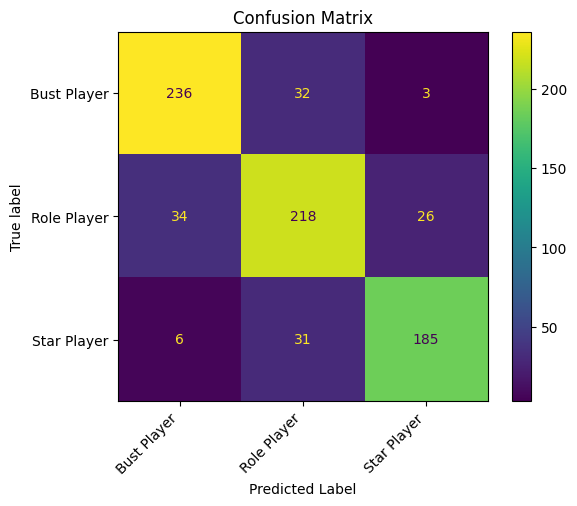

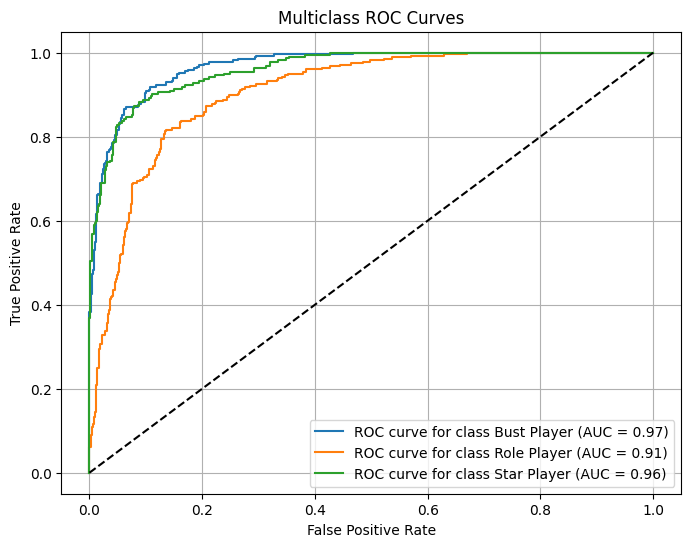

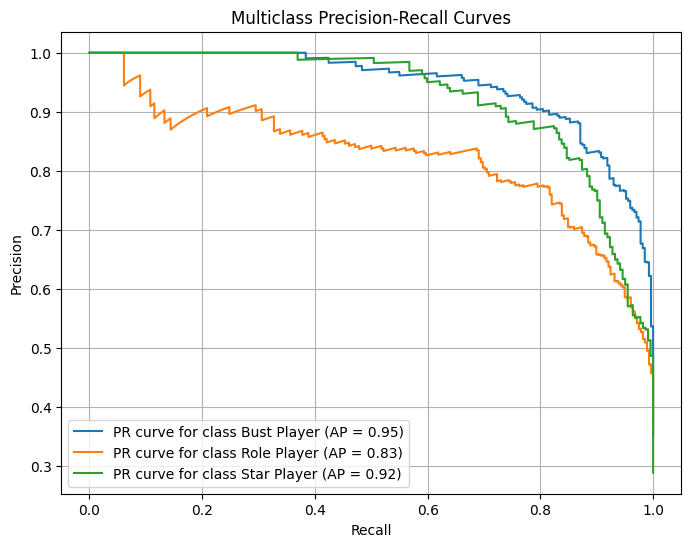

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/xgboost/training.py:183: UserWarning: [16:27:11] WARNING: /Users/runner/work/xgboost/xgboost/src/learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Fold 5 Report
              precision    recall  f1-score   support

 Bust Player       0.83      0.83      0.83       272
 Role Player       0.71      0.75      0.73       277
 Star Player       0.85      0.78      0.81       222

    accuracy                           0.79       771
   macro avg       0.80      0.79      0.79       771
weighted avg       0.79      0.79      0.79       771

Accuracy: 0.788586251621271
Precision (macro): 0.7955056421884025
Recall (macro): 0.7885228879335909
F1 Score (macro): 0.7913902166555911


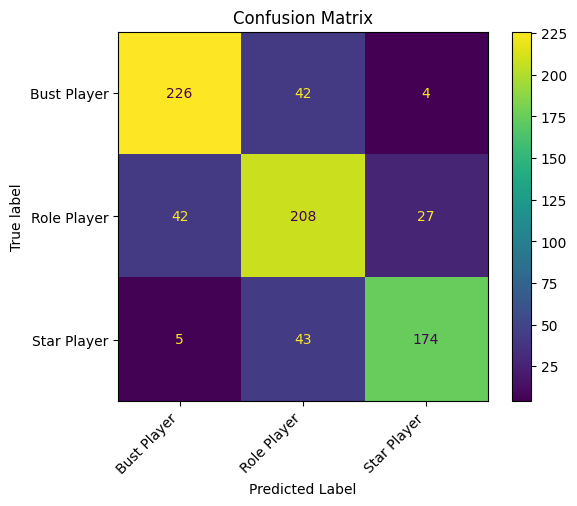

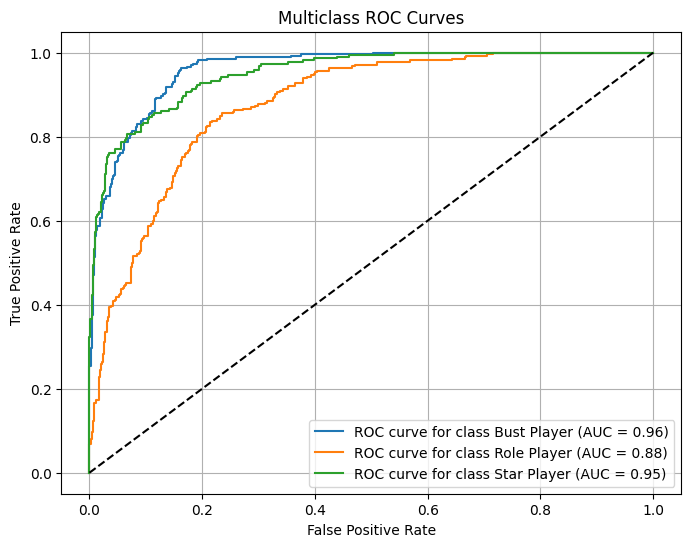

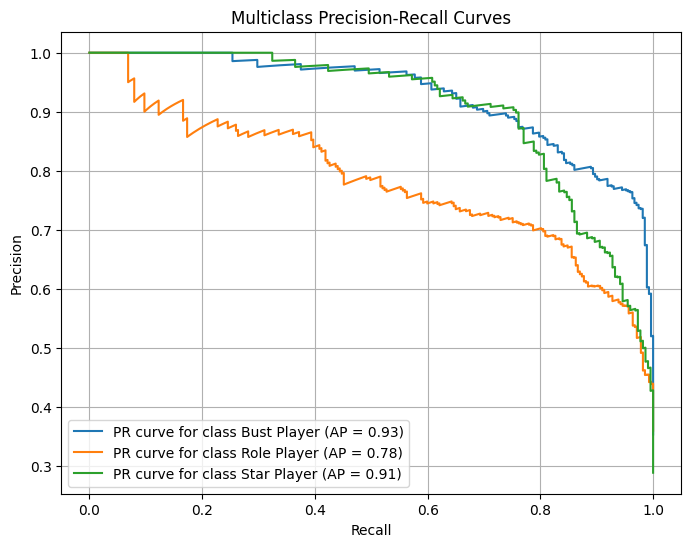

In [22]:
from sklearn.model_selection import StratifiedKFold
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

X_np = X.to_pandas()  # Convert Polars DataFrame to pandas for compatibility with preprocessor
for fold, (train_idx, test_idx) in enumerate(skf.split(X_np, y)):
    X_train, X_test = X_np.iloc[train_idx], X_np.iloc[test_idx]
    y_train, y_test = np.array(y)[train_idx], np.array(y)[test_idx]

    transformer = pipeline()
    X_train_processed = transformer.fit_transform(X_train)
    X_test_processed = transformer.transform(X_test)

    model.fit(X_train_processed, y_train)
    preds = model.predict(X_test_processed)
    
    print(f"Fold {fold + 1} Report")
    print_metrics(y_test, preds, target_names)
    print_roc_curve(y_test, model, X_test_processed, target_names)
    print_precision_recall_curve(y_test, model, X_test_processed, target_names)
    print("\n" + "="*50 + "\n")

## Logistic Regression

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


              precision    recall  f1-score   support

 Bust Player       0.86      0.90      0.88       272
 Role Player       0.76      0.77      0.77       277
 Star Player       0.87      0.80      0.83       222

    accuracy                           0.82       771
   macro avg       0.83      0.82      0.83       771
weighted avg       0.83      0.82      0.82       771

Accuracy: 0.8249027237354085
Precision (macro): 0.8286662900343181
Recall (macro): 0.8238079340755068
F1 Score (macro): 0.8256236085289325


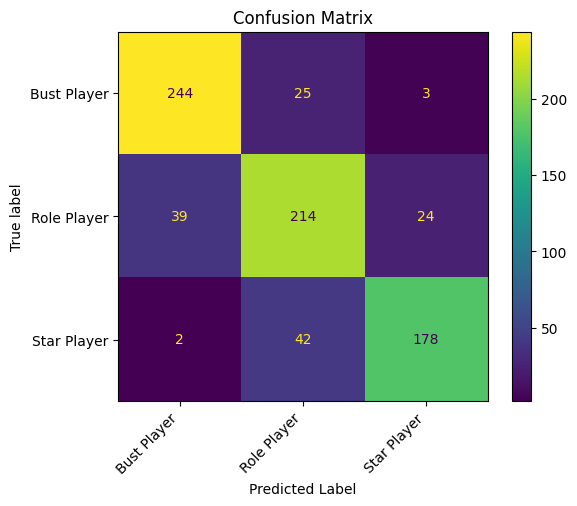

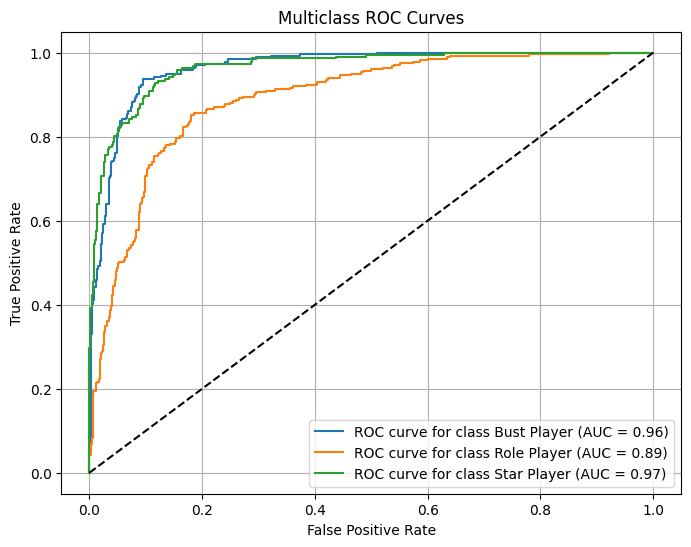

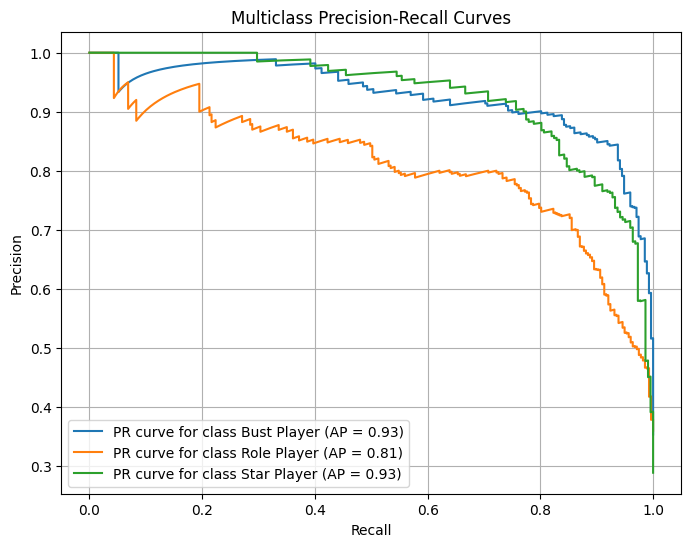

In [23]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    multi_class='multinomial', 
    max_iter=1000,
    solver='saga',
    random_state=42,
    penalty='l2',
)
model.fit(X_train_processed, y_train)
preds = model.predict(X_test_processed)
print_metrics(y_test, preds, target_names)
print_roc_curve(y_test, model, X_test_processed, target_names)
print_precision_recall_curve(y_test, model, X_test_processed, target_names)

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Random Forest Classifier with cross-validation
rf = RandomForestClassifier(random_state=42)

scores = cross_val_score(rf, X_train_processed, y_train, cv=5, scoring='accuracy')
print("RF CV Accuracy scores:", scores)
print("RF Mean CV Accuracy:", scores.mean())

# XGBoost Classifier with cross-validation
xgb = XGBClassifier(random_state=42)

scores = cross_val_score(xgb, X_train_processed, y_train, cv=5, scoring='accuracy')
print("XGB CV Accuracy scores:", scores)
print("XGB Mean CV Accuracy:", scores.mean())

# Logistic Regression Classifier with cross-validation
lr = LogisticRegression(random_state=42)

scores = cross_val_score(lr, X_train_processed, y_train, cv=5, scoring='accuracy')
print("LR CV Accuracy scores:", scores)
print("LR Mean CV Accuracy:", scores.mean())

RF CV Accuracy scores: [0.77309562 0.76823339 0.8184765  0.77471637 0.78571429]
RF Mean CV Accuracy: 0.784047233155823
XGB CV Accuracy scores: [0.78930308 0.75688817 0.80875203 0.78930308 0.80519481]
XGB Mean CV Accuracy: 0.7898882317034668
LR CV Accuracy scores: [0.80226904 0.78606159 0.83792545 0.79578606 0.82142857]
LR Mean CV Accuracy: 0.8086941421625375


Our best model is Logistic Regression with ~83% accuracy. Next, we will tune it using RandomizedSearch.

In [25]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from scipy.stats import loguniform

param_dist = {
    'C': loguniform(1e-4, 1e2),
    'penalty': ['l2'],
    'solver': ['saga', 'lbfgs'],
    'max_iter': [500, 1000, 2000],
    'multi_class': ['multinomial']
}

lr = LogisticRegression(random_state=42)
search = RandomizedSearchCV(
    lr,
    param_distributions=param_dist,
    n_iter=50,
    cv=5,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

search.fit(X_train_processed, y_train)

print("Best params:", search.best_params_)
print("Best CV score:", search.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

[CV] END C=0.0008632008168602544, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.0008632008168602544, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.017670169402947963, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.0008632008168602544, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.0008632008168602544, max_iter=2000, multi_class=multi

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

[CV] END C=0.039054412752107935, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.039054412752107935, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.4689400963537689, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.039054412752107935, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.005660670699258891, max_iter=2000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.4689400963537689, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.039054412752107935, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.4689400963537689, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.4689400963537689, max_iter=1000, multi_class=multinomial,

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/ras

... (17 outputs left out)

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


[CV] END C=14.442502135125398, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.4s
[CV] END C=14.442502135125398, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.4s
[CV] END C=33.981724150105975, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.6s


/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


[CV] END C=23.386439256208728, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.6s
[CV] END C=15.087613675681679, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.6s
Best params: {'C': np.float64(0.6688747907702062), 'max_iter': 2000, 'multi_class': 'multinomial', 'penalty': 'l2', 'solver': 'saga'}
Best CV score: 0.8090177650550423


              precision    recall  f1-score   support

 Bust Player       0.86      0.90      0.88       272
 Role Player       0.76      0.78      0.77       277
 Star Player       0.87      0.80      0.83       222

    accuracy                           0.83       771
   macro avg       0.83      0.83      0.83       771
weighted avg       0.83      0.83      0.83       771

Accuracy: 0.8261997405966277
Precision (macro): 0.8299529866740082
Recall (macro): 0.8250113035099232
F1 Score (macro): 0.8268840881177241


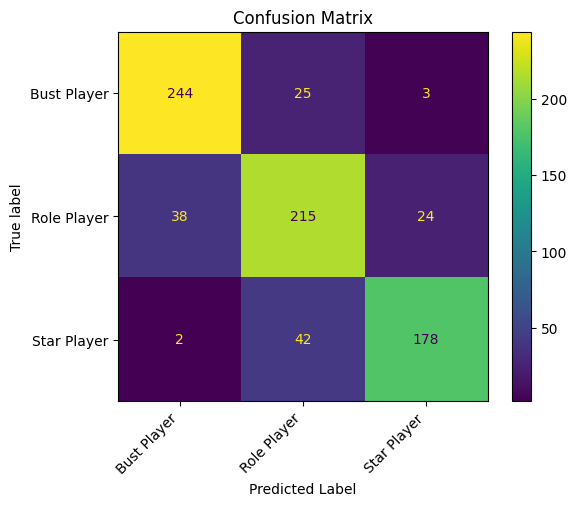

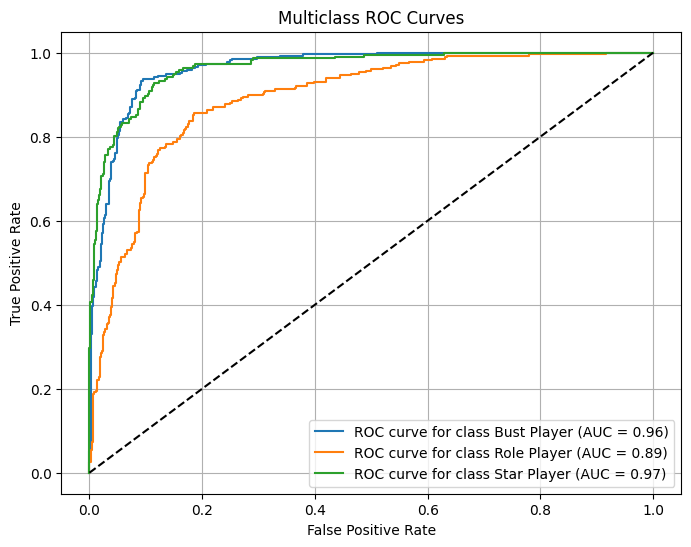

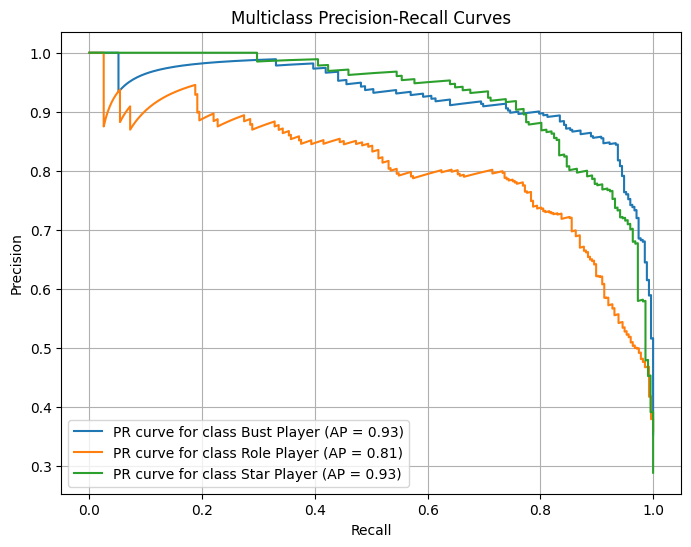

In [26]:
best_model = search.best_estimator_ 

y_pred = best_model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, best_model, X_test_processed, target_names)
print_precision_recall_curve(y_test, best_model, X_test_processed, target_names)

### Grid Search

Performing grid search to optimize hyperparameters for Logistic Regression.

In [27]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['saga', 'lbfgs'],
    'max_iter': [500, 1000, 2000],
    'multi_class': ['multinomial']
}

lr = LogisticRegression(random_state=42)
grid = GridSearchCV(
    lr,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

grid.fit(X_train_processed, y_train)
print("Best params:", grid.best_params_)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.01, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.0s
[CV] END C=0.01, max_iter=500, mu

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

[CV] END C=0.1, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.1, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.1, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.1, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.1, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.1, max_iter=1000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.1, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.1, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=0.1, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[CV] END C=0.1, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.1s
[C

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.1s
[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=10, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=1, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.4s
[CV] END C=10, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=1, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.4s
[CV] END C=1, max_iter=500, multi_class=multinomial, penalty=l2, solver=saga; total time=   0.4s
[CV] END C=10, max_iter=1000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
[CV] END C=1, max_iter=500, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s


/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

... (21 outputs left out)

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/ras

[CV] END C=10, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.5s
[CV] END C=10, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.4s
[CV] END C=100, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.4s
[CV] END C=100, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.4s


/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


[CV] END C=10, max_iter=2000, multi_class=multinomial, penalty=l2, solver=saga; total time=   1.1s
[CV] END C=10, max_iter=2000, multi_class=multinomial, penalty=l2, solver=lbfgs; total time=   0.0s
Best params: {'C': 1, 'max_iter': 1000, 'multi_class': 'multinomial', 'penalty': 'l2', 'solver': 'saga'}


              precision    recall  f1-score   support

 Bust Player       0.86      0.90      0.88       272
 Role Player       0.76      0.77      0.77       277
 Star Player       0.87      0.80      0.83       222

    accuracy                           0.82       771
   macro avg       0.83      0.82      0.83       771
weighted avg       0.83      0.82      0.82       771

Accuracy: 0.8249027237354085
Precision (macro): 0.8286662900343181
Recall (macro): 0.8238079340755068
F1 Score (macro): 0.8256236085289325


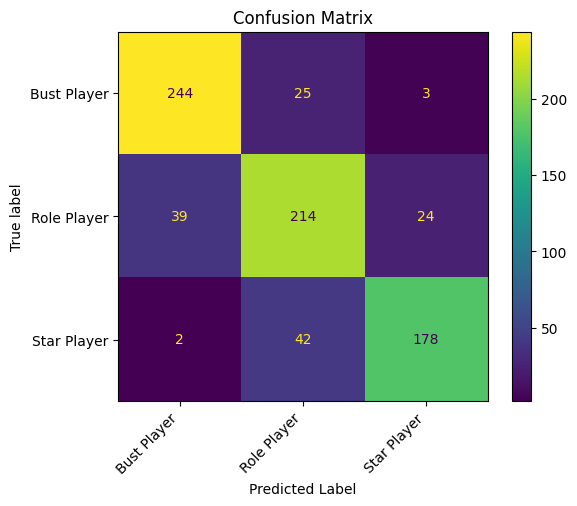

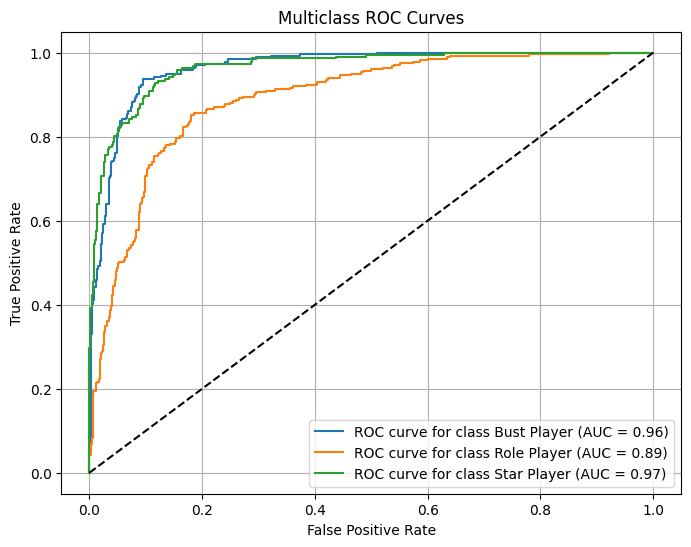

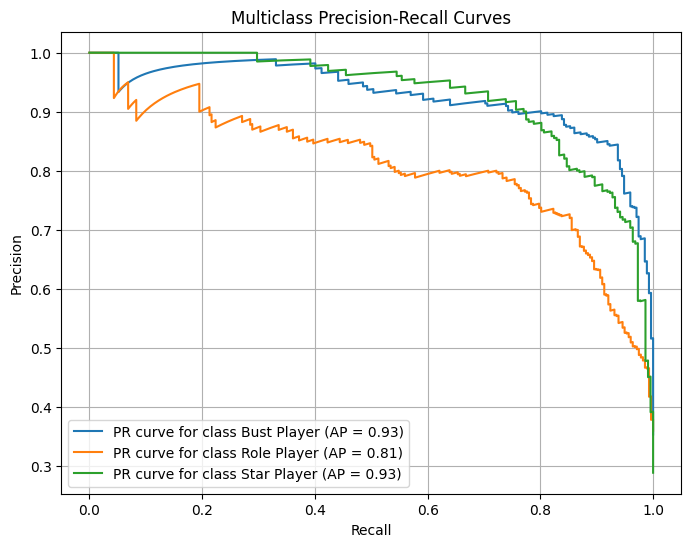

In [28]:
best_model = grid.best_estimator_  # or grid.best_estimator_

y_pred = best_model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, best_model, X_test_processed, target_names)
print_precision_recall_curve(y_test, best_model, X_test_processed, target_names)

Lets look at the other models to be sure

In [105]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

rf = RandomForestClassifier(random_state=42)
rf_grid = GridSearchCV(
    rf,
    param_grid=rf_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

rf_grid.fit(X_train_processed, y_train)
print("Best RF params:", rf_grid.best_params_)
print("Best RF CV score:", rf_grid.best_score_)

Fitting 5 folds for each of 216 candidates, totalling 1080 fits


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  return _ForkingPickler.loads(res)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/multiprocessing/queues.py:120: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for 

[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.5s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.5s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.5s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.5s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.5s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.0s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.0s
[CV] END bootstrap=True, max_depth=None, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=   1.0s
[CV] END bootstrap=True, max_depth=None, min_sam

              precision    recall  f1-score   support

 Bust Player       0.86      0.87      0.86       271
 Role Player       0.74      0.77      0.75       277
 Star Player       0.84      0.78      0.81       223

    accuracy                           0.81       771
   macro avg       0.81      0.81      0.81       771
weighted avg       0.81      0.81      0.81       771

Accuracy: 0.8093385214007782
Precision (macro): 0.8133610163782578
Recall (macro): 0.808158403903574
F1 Score (macro): 0.8102952138719771


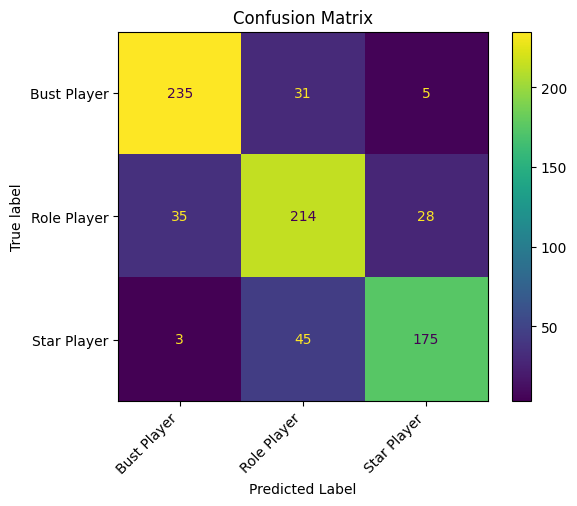

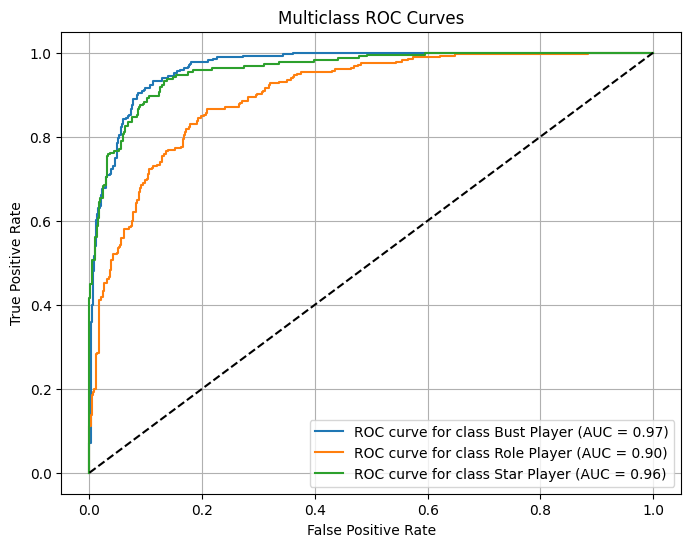

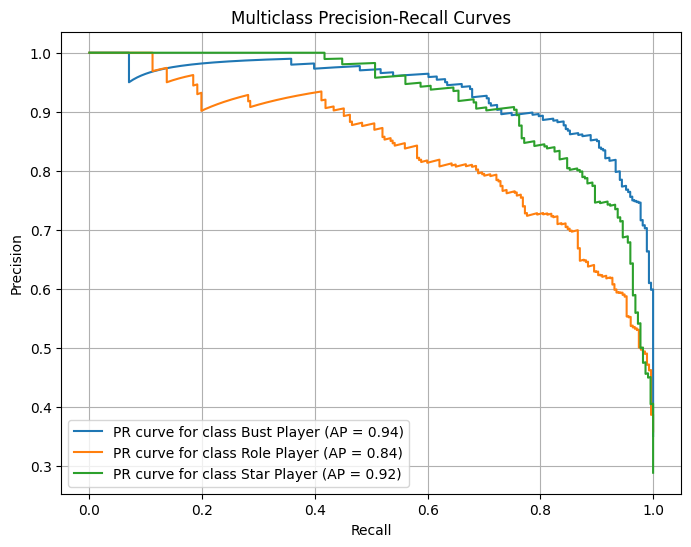

In [106]:
best_model = grid.best_estimator_  # or grid.best_estimator_

y_pred = best_model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, best_model, X_test_processed, target_names)
print_precision_recall_curve(y_test, best_model, X_test_processed, target_names)

In [107]:
xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7, 10],
    'learning_rate': [0.01, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    xgb,
    param_grid=xgb_param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=2
)

xgb_grid.fit(X_train_processed, y_train)
print("Best XGB params:", xgb_grid.best_params_)
print("Best XGB CV score:", xgb_grid.best_score_)


Fitting 5 folds for each of 144 candidates, totalling 720 fits
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=0.8; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.2s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=3, n_estimators=100, subsample=1.0; total time=   0.2s
[CV] END 

              precision    recall  f1-score   support

 Bust Player       0.85      0.85      0.85       271
 Role Player       0.73      0.77      0.75       277
 Star Player       0.86      0.80      0.83       223

    accuracy                           0.80       771
   macro avg       0.81      0.80      0.81       771
weighted avg       0.81      0.80      0.80       771

Accuracy: 0.8041504539559015
Precision (macro): 0.8100799119160844
Recall (macro): 0.8040592656011553
F1 Score (macro): 0.806562142379199


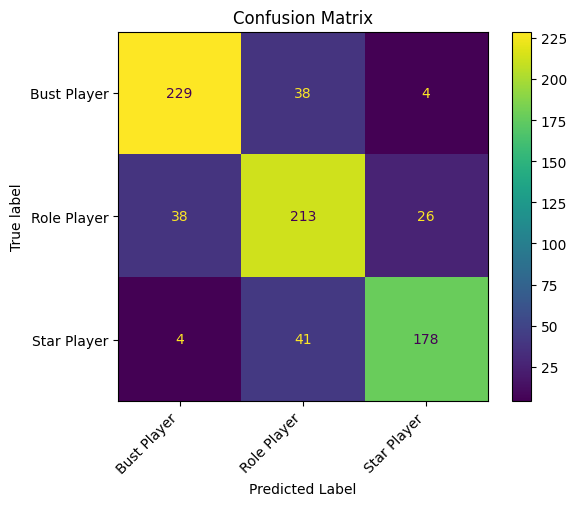

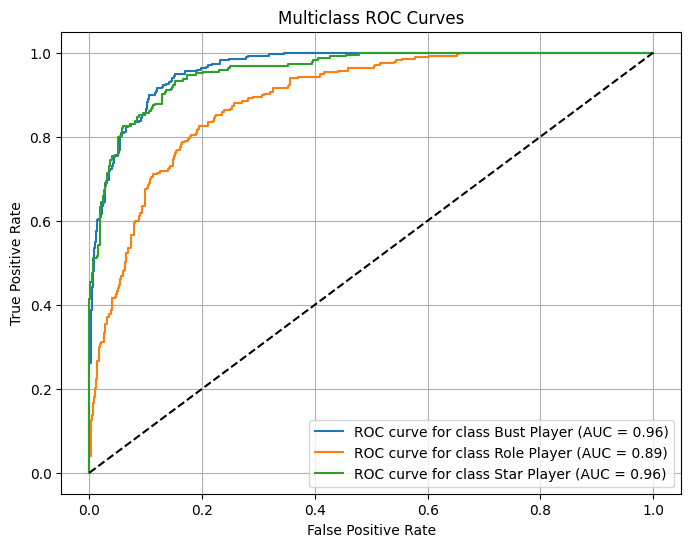

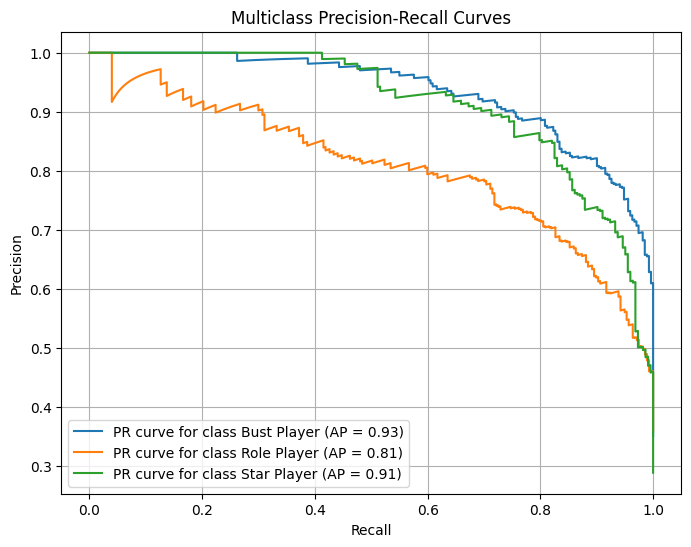

In [109]:
best_model = xgb_grid.best_estimator_  # or grid.best_estimator_

y_pred = best_model.predict(X_test_processed)
print_metrics(y_test, y_pred, target_names)
print_roc_curve(y_test, best_model, X_test_processed, target_names)
print_precision_recall_curve(y_test, best_model, X_test_processed, target_names)

## Save the Best Model

Save the best trained model to disk for future use.

In [29]:
import joblib
# Save the model
model_path = Path.cwd().parent / "models"
model_path.mkdir(exist_ok=True, parents=True)
joblib.dump(best_model, model_path / "logistic_regression_model.pkl")

['/Users/rashe/PycharmProjects/PredictingNBACareers/notebooks/models/logistic_regression_model.pkl']

In [32]:
# Save the pipeline with model attached
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline(steps=[
    ('preprocessor', pipeline()),
    ('model', best_model)
])
lr_pipeline.fit(X_train, y_train)
# Save the pipeline

joblib.dump(lr_pipeline, model_path / "lr_pipeline_model.pkl")

/Users/rashe/PycharmProjects/PredictingNBACareers/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


['/Users/rashe/PycharmProjects/PredictingNBACareers/notebooks/models/lr_pipeline_model.pkl']

# Testing Model

In [103]:
test = df.filter(pl.col("Player").str.to_lowercase() == "Cam Reddish".lower())
test

Player,Season,Player_Age,2P,2P%,2PA,3P,3P%,3PA,3PAr,AST,AST%,BLK,BLK%,BPM,DBPM,DRB,DRB%,DWS,FG,FG%,FGA,FT,FT%,FTA,FTr,G,GS,MP,OBPM,ORB,ORB%,OWS,PER,PF,PTS,STL,…,FT%_third,FTA_third,FTr_third,G_third,GS_third,MP_third,OBPM_third,ORB_third,ORB%_third,OWS_third,PER_third,PF_third,PTS_third,Player_Age_third,STL_third,STL%_third,TOV_third,TOV%_third,TRB_third,TRB%_third,TS%_third,Trp-Dbl_third,USG%_third,VORP_third,WS_third,WS/48_third,eFG%_third,All_Nba_Team_Max,AllStar_Max,Games_Played_Mean,Win_Share_Sum,Box_Plus_Minus_Mean,Minutes_Played_Mean,Games_Started_Mean,Usage_Mean,Player_Score,Player_Label
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,bool,f64,f64,f64,f64,f64,f64,f64,str
"""Cam Reddish""",2019,20.0,130.0,0.428,304.0,83.0,0.332,250.0,0.451,87.0,8.0,28.0,1.5,-4.2,-1.0,181.0,12.7,0.8,213.0,0.384,554.0,101.0,0.802,126.0,0.227,58.0,34.0,1551.0,-3.3,35.0,2.4,-1.2,9.0,132.0,610.0,62.0,…,0.902,112.0,0.275,49.0,7.0,1012.0,-1.0,25.0,2.7,0.2,12.8,60.0,497.0,22.0,47.0,2.3,57.0,11.1,105.0,5.7,0.543,0.0,22.2,0.2,1.0,0.046,0.485,0,false,41.75,5.0,-3.1,982.0,19.5,16.65,0.365451,"""Role Player"""


In [104]:
loaded_model = joblib.load(model_path / "lr_pipeline_model.pkl")

import numpy as np

# Testing predictions
X = test.drop("Player")

# Outside the pipeline
player_label_order = ["Bust Player", "Role Player", "Star Player"]
try:
    y_pred = loaded_model.predict(X)
    y_prob = loaded_model.predict_proba(X)
except Exception as e:
    print(f"We do not have that player data! Error during prediction: {e}")
else:
    # Convert prediction to label using player_label_order
    predicted_label = player_label_order[int(y_pred[0])]
    display(predicted_label)
    # Show probabilities with class labels
    prob_df = pl.DataFrame(y_prob, schema=player_label_order)
    prob_df_rounded = prob_df.with_columns(
        pl.all().round(2)
    )
    display(prob_df_rounded)

'Role Player'

Bust Player,Role Player,Star Player
f64,f64,f64
0.0,0.61,0.39
